In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

# RandomForestClassifier removed because it triggers a DLL load policy error.
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

data_path = Path("../data/processed_credit_default.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (30000, 32)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,PAY_AMT5,PAY_AMT6,default payment next month,delayed_months,max_payment_delay,avg_bill_amount,avg_payment_amount,total_payment_amount,recent_bill_to_limit_ratio,recent_payment_to_bill_ratio
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,1,2,2,1284.000000,114.833333,689,0.195650,0.000000
1,2,120000,2,2,2,26,-1,2,0,0,...,0,2000,1,2,2,2846.166667,833.333333,5000,0.022350,0.000000
2,3,90000,2,2,2,34,0,0,0,0,...,1000,5000,0,0,0,16942.166667,1836.333333,11018,0.324878,0.051915
3,4,50000,2,2,1,37,0,0,0,0,...,1069,1000,0,0,0,38555.666667,1398.000000,8388,0.939800,0.042561
4,5,50000,1,2,1,57,-1,0,-1,0,...,689,679,0,0,0,18223.166667,9841.500000,59049,0.172340,0.232072


Verify Target & Engineered Features

In [4]:
target = "default payment next month"

engineered_features = [
    "delayed_months",
    "max_payment_delay",
    "avg_bill_amount",
    "avg_payment_amount",
    "total_payment_amount",
    "recent_bill_to_limit_ratio",
    "recent_payment_to_bill_ratio"
]

assert target in df.columns, "Target column is missing!"

missing_features = [
    col for col in engineered_features
    if col not in df.columns
]

assert not missing_features, f"Missing features: {missing_features}"

print("Target distribution:")
print(df[target].value_counts())

print("\nTarget proportions:")
print(df[target].value_counts(normalize=True).round(4))

print("\nEngineered feature summary:")
display(df[engineered_features].describe().T)

Target distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target proportions:
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
delayed_months,30000.0,0.834200,1.554303,0.000000,0.000000,0.000000,1.000000,6.000000e+00
max_payment_delay,30000.0,0.682200,1.073518,0.000000,0.000000,0.000000,2.000000,8.000000e+00
avg_bill_amount,30000.0,44976.945200,63260.721860,-56043.166667,4781.333333,21051.833333,57104.416667,8.773138e+05
avg_payment_amount,30000.0,5275.232094,10137.946323,0.000000,1113.291667,2397.166667,5583.916667,6.273443e+05
total_payment_amount,30000.0,31651.392567,60827.677939,0.000000,6679.750000,14383.000000,33503.500000,3.764066e+06
recent_bill_to_limit_ratio,30000.0,0.423771,0.411462,-0.619892,0.022032,0.313994,0.829843,6.455300e+00
recent_payment_to_bill_ratio,30000.0,99.128560,2692.818701,0.000000,0.035244,0.057385,0.294092,2.988870e+05


Check for Infinite & Missing Values

In [5]:
print("Infinite values:")
print(
    np.isinf(df[engineered_features])
    .sum()
)

print("\nMissing values:")
print(df[engineered_features].isna().sum())

Infinite values:
delayed_months                  0
max_payment_delay               0
avg_bill_amount                 0
avg_payment_amount              0
total_payment_amount            0
recent_bill_to_limit_ratio      0
recent_payment_to_bill_ratio    0
dtype: int64

Missing values:
delayed_months                  0
max_payment_delay               0
avg_bill_amount                 0
avg_payment_amount              0
total_payment_amount            0
recent_bill_to_limit_ratio      0
recent_payment_to_bill_ratio    0
dtype: int64


Analyze Feature Corelation

In [6]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

target_correlation = (
    correlation_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
)

print("Features most positively correlated with default:")
display(target_correlation.head(15))

print("Features most negatively correlated with default:")
display(target_correlation.tail(15))

Features most positively correlated with default:


delayed_months                  0.398394
max_payment_delay               0.370388
PAY_0                           0.324794
PAY_2                           0.263551
PAY_3                           0.235253
PAY_4                           0.216614
PAY_5                           0.204149
PAY_6                           0.186866
recent_bill_to_limit_ratio      0.086168
EDUCATION                       0.033842
AGE                             0.013890
BILL_AMT6                      -0.005372
BILL_AMT5                      -0.006760
recent_payment_to_bill_ratio   -0.006950
BILL_AMT4                      -0.010156
Name: default payment next month, dtype: float64

Features most negatively correlated with default:


ID                     -0.013952
BILL_AMT3              -0.014076
BILL_AMT2              -0.014193
BILL_AMT1              -0.019644
MARRIAGE               -0.027575
SEX                    -0.039961
PAY_AMT6               -0.053183
PAY_AMT5               -0.055124
PAY_AMT3               -0.056250
PAY_AMT4               -0.056827
PAY_AMT2               -0.058579
PAY_AMT1               -0.072929
avg_payment_amount     -0.102354
total_payment_amount   -0.102354
LIMIT_BAL              -0.153520
Name: default payment next month, dtype: float64

Visualize the Strongest Relationships

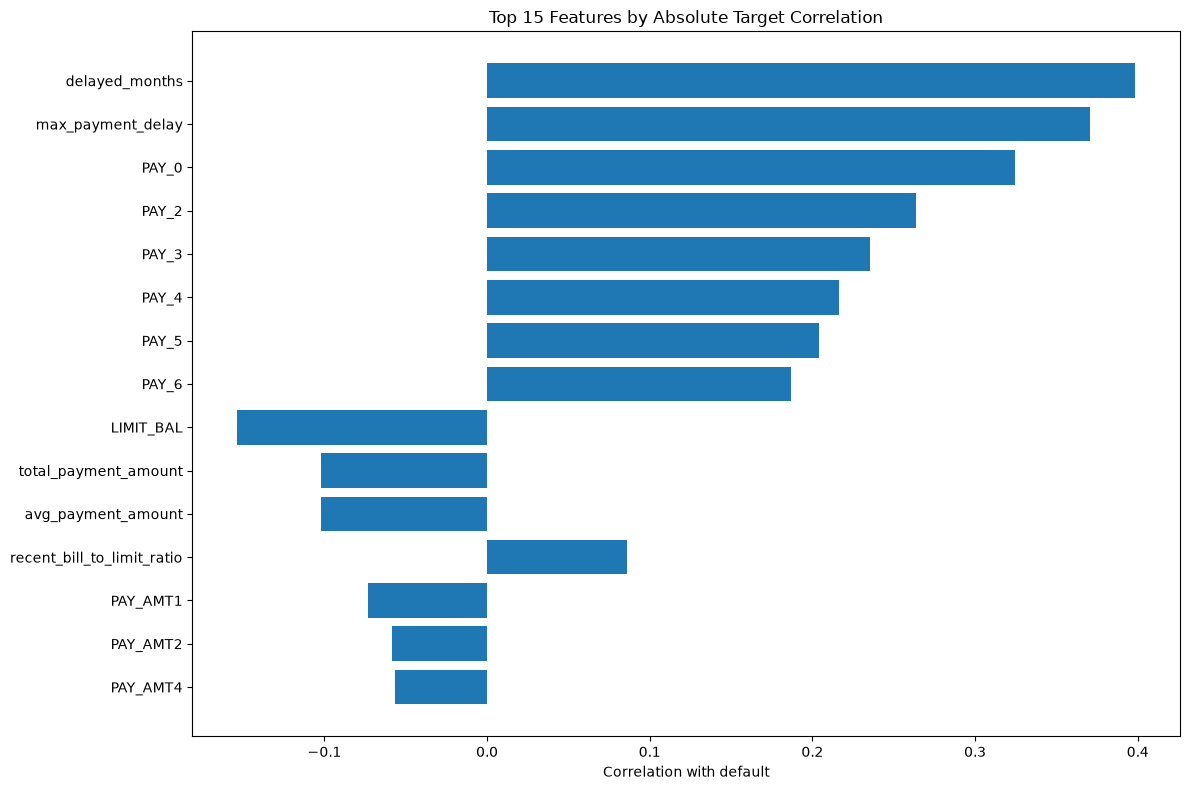

In [7]:
top_features = (
    target_correlation.abs()
    .sort_values(ascending=False)
    .head(15)
    .index
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features,
    target_correlation.loc[top_features]
)

plt.xlabel("Correlation with default")
plt.title("Top 15 Features by Absolute Target Correlation")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Investigate Corelation Among Predictors

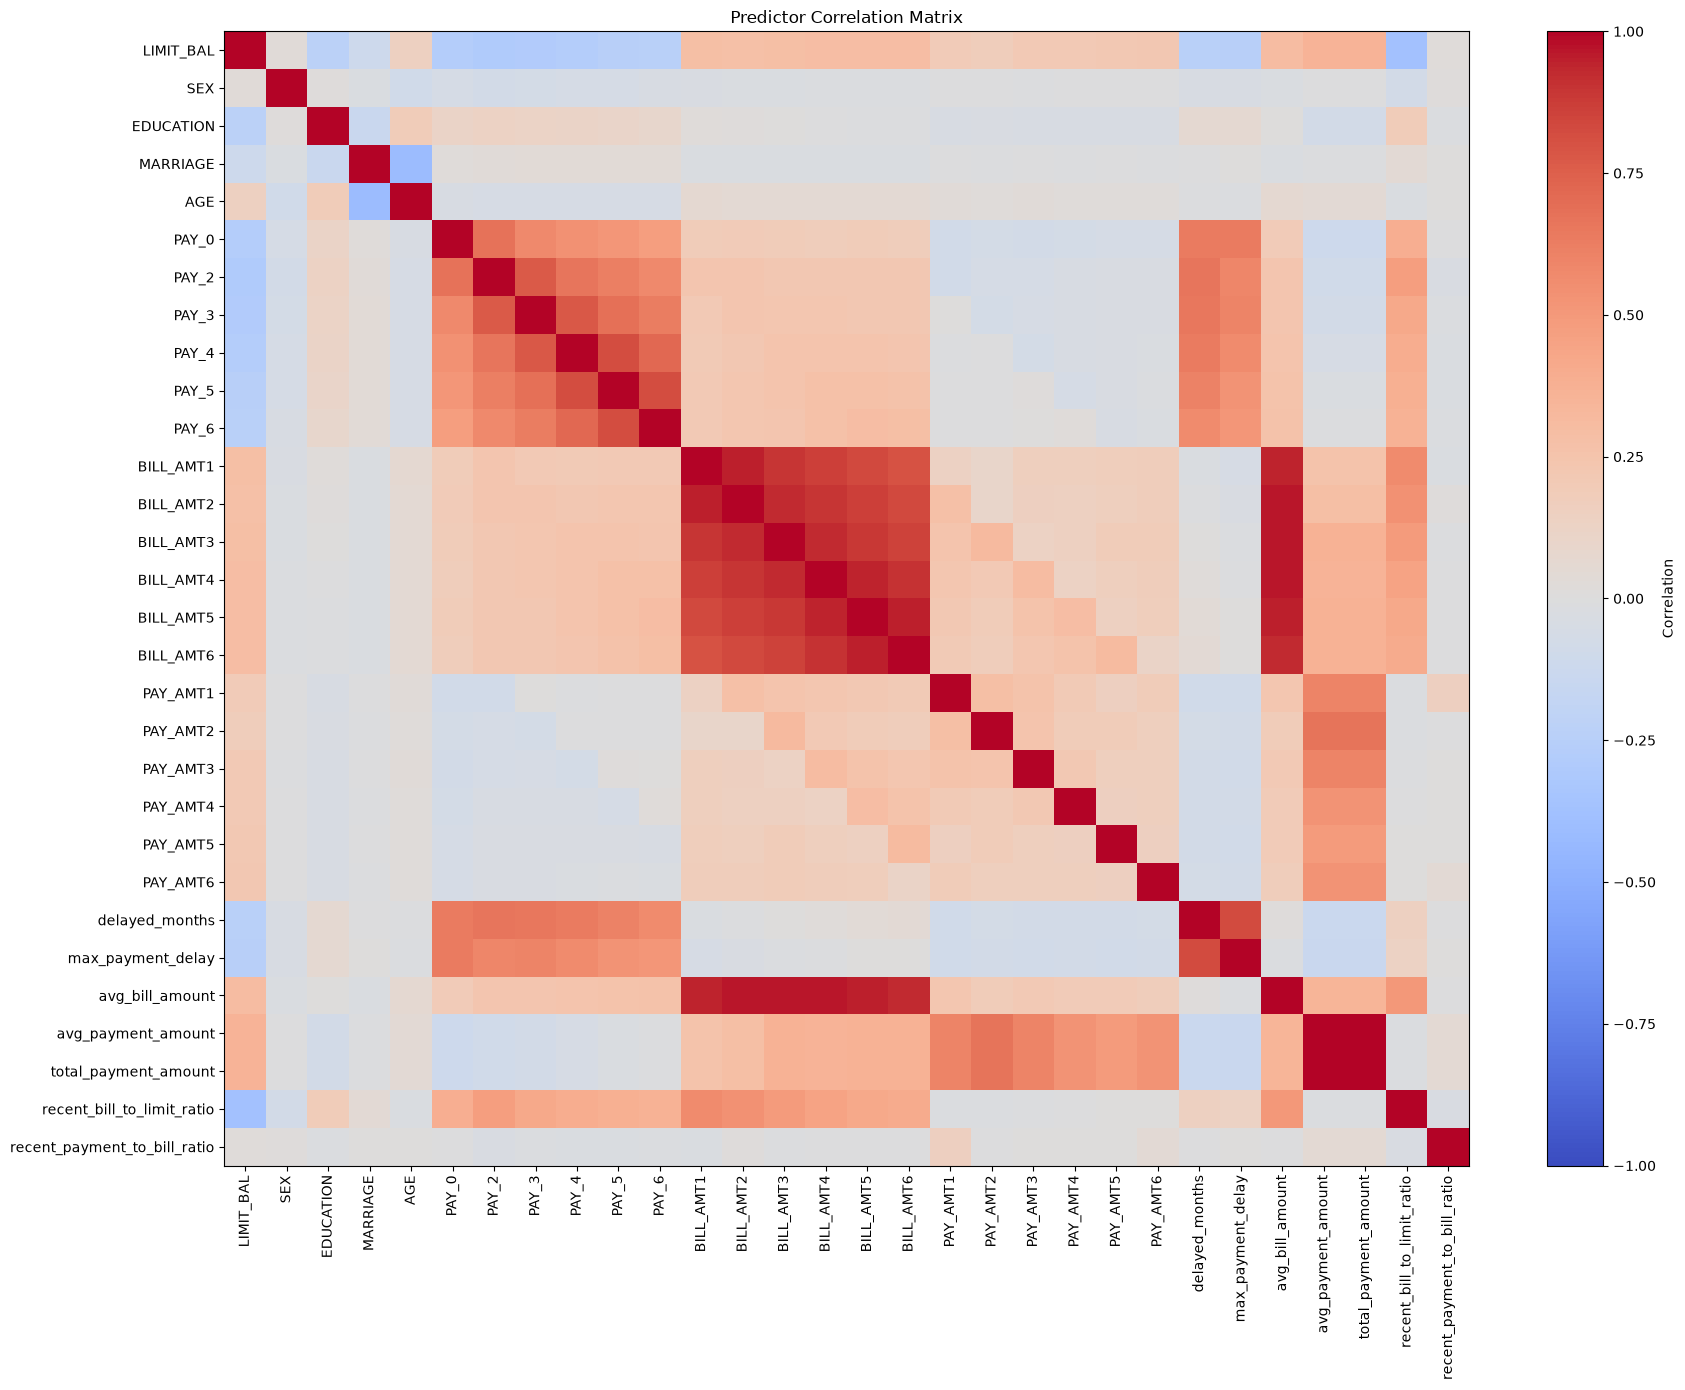

In [8]:
predictor_corr = numeric_df.drop(
    columns=[target, "ID"],
    errors="ignore"
).corr()

plt.figure(figsize=(18, 14))

plt.imshow(
    predictor_corr,
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")
plt.xticks(
    range(len(predictor_corr.columns)),
    predictor_corr.columns,
    rotation=90
)
plt.yticks(
    range(len(predictor_corr.columns)),
    predictor_corr.columns
)

plt.title("Predictor Correlation Matrix")
plt.tight_layout()
plt.show()

Create two feature sets

In [9]:
original_features = [
    col for col in df.columns
    if col not in [target, "ID"] + engineered_features
]

all_features = original_features + engineered_features

X_original = df[original_features].copy()
X_engineered = df[all_features].copy()

y = df[target].astype(int)

print("Original feature count:", len(original_features))
print("Engineered feature count:", len(all_features))
print("Additional engineered features:", len(engineered_features))

Original feature count: 23
Engineered feature count: 30
Additional engineered features: 7


Split the Dataset without Leakage

In [10]:
train_val_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y.loc[train_val_idx]
)

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Testing records:", len(test_idx))

Training records: 19200
Validation records: 4800
Testing records: 6000


Check the Class Proportions

In [11]:
for name, indices in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:
    print(f"\n{name} distribution:")
    print(y.loc[indices].value_counts(normalize=True).round(4))


Training distribution:
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Validation distribution:
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Testing distribution:
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


Build Preprocessing Pipeline

In [12]:
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

def create_preprocessor(feature_columns, scale_numeric=True):

    numerical_features = [
        col for col in feature_columns
        if col not in categorical_features
    ]

    if scale_numeric:
        numerical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        numerical_transformer = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median"))
        ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, numerical_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    return preprocessor

Train & Compare Two Models

In [13]:
def create_models(feature_columns):

    models = {
        "Logistic Regression": Pipeline(steps=[
            ("preprocessor", create_preprocessor(
                feature_columns,
                scale_numeric=True
            )),
            ("classifier", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ]),

        "Random Forest": Pipeline(steps=[
            ("preprocessor", create_preprocessor(
                feature_columns,
                scale_numeric=False
            )),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    }

    return models

Evaluate Models

In [16]:
feature_sets = {
    "Original Features": X_original,
    "Original + Engineered": X_engineered
}

results = []
trained_models = {}

for feature_set_name, X_data in feature_sets.items():

    X_train = X_data.loc[train_idx]
    X_val = X_data.loc[val_idx]

    y_train = y.loc[train_idx]
    y_val = y.loc[val_idx]

    models = create_models(X_data.columns.tolist())

    for model_name, model in models.items():

        print(f"Training: {model_name} | {feature_set_name}")

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)
        probabilities = model.predict_proba(X_val)[:, 1]

        result = {
            "Feature Set": feature_set_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_val, probabilities
            )
        }

        results.append(result)

        trained_models[
            (feature_set_name, model_name)
        ] = model

Training: Logistic Regression | Original Features
Training: Random Forest | Original Features
Training: Logistic Regression | Original + Engineered
Training: Random Forest | Original + Engineered


Display the Comparison

In [17]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)

,Feature Set,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Original + Engineered,Random Forest,0.8048,0.5676,0.4944,0.5284,0.7774
1,Original Features,Random Forest,0.8046,0.5674,0.4915,0.5267,0.7760
2,Original + Engineered,Logistic Regression,0.7429,0.4420,0.6177,0.5153,0.7533
0,Original Features,Logistic Regression,0.6908,0.3834,0.6535,0.4833,0.7254


Examine best Model

In [18]:
best_row = results_df.loc[results_df["F1"].idxmax()]

best_feature_set = best_row["Feature Set"]
best_model_name = best_row["Model"]

best_model = trained_models[
    (best_feature_set, best_model_name)
]

print("Best validation candidate:")
print(best_row)

Best validation candidate:
Feature Set    Original + Engineered
Model                  Random Forest
Accuracy                    0.804792
Precision                   0.567568
Recall                       0.49435
F1                          0.528435
ROC-AUC                     0.777382
Name: 3, dtype: object


Confusion Matrix & Classification Report

In [19]:
X_val_best = feature_sets[best_feature_set].loc[val_idx]
y_val = y.loc[val_idx]

val_predictions = best_model.predict(X_val_best)

print("Confusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_predictions,
        target_names=["No Default", "Default"],
        zero_division=0
    )
)

Confusion Matrix:
[[3338  400]
 [ 537  525]]

Classification Report:
              precision    recall  f1-score   support

  No Default       0.86      0.89      0.88      3738
     Default       0.57      0.49      0.53      1062

    accuracy                           0.80      4800
   macro avg       0.71      0.69      0.70      4800
weighted avg       0.80      0.80      0.80      4800



Save Results

In [20]:
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    reports_dir / "day9_model_comparison.csv",
    index=False
)

target_correlation.to_csv(
    reports_dir / "day9_target_correlations.csv"
)

print("Day 9 reports saved successfully!")

Day 9 reports saved successfully!
